In [4]:
from anemone.forwards import ForwardLaplace3
from anemone import constants as c
from anemone.transforms import Hankel, invLaplace
from anemone.physics import rte_matrix as rte, freespace_u0 as u0, drte_dsigma
from anemone.physics import refl_transverse_electric as rte0
import torch
from numpy import ndarray
import matplotlib.pyplot as plt
import numpy as np


In [5]:
from anemone.physics import *
def calc_rte_matrix1(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0, collapse_matrices=True):
    thick = torch.vstack([torch.zeros_like(thickness[:1]), thickness])

    lambda2 = wave_length**2
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    un = torch.sqrt(lambda2 - k2)
    u0 = freespace_u0(omega, wave_length)
    un1 = torch.roll(un, 1, dims=0)
    un1[0] = u0
    un2 = un*1.

    euh_p = torch.exp(un1*thick)

    euh_m = 1./euh_p
    unratio = un2/un1
    d_un  = 1.-unratio
    m_un  = 1.+unratio

    propmat = torch.empty(m_un.shape+(2,2), dtype=torch.complex128)
    propmat[..., 0, 0] = m_un*euh_p
    propmat[..., 0, 1] = d_un*euh_p
    propmat[..., 1, 0] = d_un*euh_m
    propmat[..., 1, 1] = m_un*euh_m

    answer = torch.tensor([1., 0.], dtype=torch.complex128, device=thickness.device)
    answer = propmat[-1] @ answer
    for i in range(propmat.shape[0]-2, -1, -1):
        answer = torch.einsum('...ij,...j->...i', propmat[i], answer)
    rte = answer[..., 1] / answer[..., 0]
    return rte

def rte_matrix1(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    rte = calc_rte_matrix1(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon)
    return torch.nan_to_num(rte)

In [6]:
from anemone.physics import *
def calc_prop_matrix(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0, pad=0):
    thick = torch.vstack([torch.zeros_like(thickness[:1]), thickness])

    lambda2 = wave_length**2
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    un = torch.sqrt(lambda2 - k2)
    u0 = freespace_u0(omega, wave_length)
    un1 = torch.roll(un, 1, dims=0)
    un1[0] = u0
    un2 = un*1.

    euh_p = torch.exp(un1*thick)

    euh_m   = 1./euh_p
    unratio = un2/un1
    d_un    = 1.-unratio
    m_un    = 1.+unratio

    propmat = torch.zeros((2,2, m_un.shape[0]+pad)+m_un.shape[1:], dtype=torch.complex128)
    if pad>0:
        propmat[0,0,:pad] = 1.
        propmat[1,1,:pad] = 1.

        propmat[0, 0, pad:] = m_un*euh_p
        propmat[0, 1, pad:] = d_un*euh_p
        propmat[1, 0, pad:] = d_un*euh_m
        propmat[1, 1, pad:] = m_un*euh_m
    else:
        propmat[0, 0] = m_un*euh_p
        propmat[0, 1] = d_un*euh_p
        propmat[1, 0] = d_un*euh_m
        propmat[1, 1] = m_un*euh_m
    return propmat

plot = True
def calc_dpropmat(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):

    pad = 4

    propmat = calc_prop_matrix(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, pad=pad)
    propmat = torch.roll(propmat, -pad//2, dims=2)
    if plot:
        fig,axs = plt.subplots(2, propmat.shape[2]//2,  figsize=(10, 3))
        for i,ax in enumerate(axs.flat):
            pcm = ax.matshow(propmat[:, :, i, 0,0].real.cpu().numpy(), cmap='seismic', vmin=-1, vmax=1)
            ax.set_title(f'{i}')
            ax.axis('off')
        plt.colorbar(pcm, ax=axs.ravel().tolist(), shrink=0.8)
        fig.suptitle('propmat')

    answer = torch.zeros((2,)+propmat.shape[2:], dtype=torch.complex128, device=thickness.device)
    print('shape of answer', answer.shape)
    answer[0, :] = 1.
    for i in range(answer.shape[1]-2, -1, -1):
        answer[:, i] = torch.einsum('ij...,j...->i...', propmat[:,:,i], answer[:, i+1])

    for i in range(1, propmat.shape[2]):
        propmat[:,:,i] = torch.einsum('ij...,jk...->ik...', propmat[:,:, i-1], propmat[:,:, i])

    if plot:
        fig,axs = plt.subplots(2, propmat.shape[2]//2,  figsize=(10, 3))
        for i,ax in enumerate(axs.flat):
            pcm = ax.matshow(propmat[:, :, i, 0,0].real.cpu().numpy(), cmap='seismic', vmin=-1, vmax=1)
            ax.set_title(f'{i}')
            ax.axis('off')
        plt.colorbar(pcm, ax=axs.ravel().tolist(), shrink=0.8)
        fig.suptitle('cumulative propmat')
        
        fig,axs = plt.subplots(2, propmat.shape[2]//2,  figsize=(10, 3))
        for i,ax in enumerate(axs.flat):
            pcm = ax.matshow(answer[:, None, i, 0,0].real.cpu().numpy(), cmap='seismic', vmin=-1, vmax=1)
            ax.set_title(f'{i}')
            ax.axis('off')
        plt.colorbar(pcm, ax=axs.ravel().tolist(), shrink=0.8)    
        fig.suptitle('RTE state')
    
    # propmat = torch.roll(propmat, -2, dims=2)
    rte = answer[1, 0] / answer[0, 0]

    answer = torch.roll(answer, -1, dims=1)
    answer[0,-2-pad//2:] = 1.
    answer[1,-2-pad//2:] = 0.
    
    dsigma = sigma.clone()
    dsigma[::2] *= 1.02
    dpropmat = calc_prop_matrix(dsigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, pad=pad)
    dpropmat = torch.roll(dpropmat, -pad//2, dims=2)

    if plot:
        fig,axs = plt.subplots(2, dpropmat.shape[2]//2,  figsize=(10, 3))
        for i,ax in enumerate(axs.flat):
            pcm = ax.matshow(dpropmat[:, :, i, 0,0].real.cpu().numpy(), cmap='seismic', vmin=-1, vmax=1)
            ax.set_title(f'{i}')
            ax.axis('off')
        plt.colorbar(pcm, ax=axs.ravel().tolist(), shrink=0.8)
        fig.suptitle('dpropmat')

    # dpropmat = torch.roll(dpropmat, -3, dims=2)
    
    # fig,axs = plt.subplots(2, dpropmat.shape[2]//2,  figsize=(10, 3))
    # for i,ax in enumerate(axs.flat):
    #     pcm = ax.matshow(dpropmat[:, :, i, 0,0].real.cpu().numpy(), cmap='seismic', vmin=-1, vmax=1)
    #     ax.set_title(f'{i}')
    #     ax.axis('off')
    # plt.colorbar(pcm, ax=axs.ravel().tolist(), shrink=0.8)
    # fig.suptitle('dpropmat -> roll(-3)')

    drte = torch.einsum('ij...,j...->i...', dpropmat, answer)
    drte = torch.roll(drte, -1, dims=1)
    drte[0,-1:] = 1.
    drte[1,-1:] = 0.

    drte = torch.einsum('ij...,j...->i...', dpropmat, drte)
    # dpropmat = torch.roll(drte, -1, dims=1)
    # drte[0,-1:] = 1.
    # drte[1,-1:] = 0.    
    drte = torch.einsum('ij...,j...->i...', propmat, drte)
    # drte = torch.roll(drte, 1, dims=1)

    dsigma = sigma.clone()
    dsigma[1::2] *= 1.02
    dpropmat = calc_prop_matrix(dsigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, pad=pad)
    dpropmat = torch.roll(dpropmat, -pad//2, dims=2)

    
    drte2 = torch.einsum('ij...,j...->i...', dpropmat, answer)
    drte2 = torch.roll(drte2, -1, dims=1)
    drte2 = torch.einsum('ij...,j...->i...', dpropmat, drte2)
    drte2 = torch.roll(drte2, -1, dims=1)
    drte2 = torch.einsum('ij...,j...->i...', propmat, drte2)

    drte[:, 1::2] = drte2[:, 1::2]
    return ((drte[1, 1:-3]/drte[0, 1:-3]) - rte), rte#/(sigma*0.02), rte

In [20]:
from anemone.physics import *

def calc_dpropmat(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):

    pad = 1

    propmat = calc_prop_matrix(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, pad=pad)

    answer = torch.zeros((2,)+propmat.shape[2:], dtype=torch.complex128, device=thickness.device)
    
    answer[0, :] = 1.
    for i in range(answer.shape[1]-2, -1, -1):
        answer[:, i] = torch.einsum('ij...,j...->i...', propmat[:,:,i], answer[:, i+1])

    for i in range(1, propmat.shape[2]):
        propmat[:,:,i] = torch.einsum('ij...,jk...->ik...', propmat[:,:, i-1], propmat[:,:, i])

    rte = answer[1, 0] / answer[0, 0]

    answer = torch.roll(answer, -1, dims=1)
    answer[0,-1:] = 1.
    answer[1,-1:] = 0.
    
    # rte0 = torch.einsum('ij...,j...->i...', propmat, answer).squeeze()
    # rte0 = rte0[1] / rte0[0]
    # print('rte0', rte0.shape)
    # plt.figure()
    # plt.semilogy( rte0.squeeze().real.cpu().numpy(), 'C0')
    # plt.semilogy(-rte0.squeeze().real.cpu().numpy(), 'C0--')
    # plt.semilogy([0],  rte.real[0].cpu().numpy(), 'k*')
    # plt.semilogy([0],  rte.imag[0].cpu().numpy(), 'ko')
    # # plt.semilogy(np.arange(len(rte0)), rte.real, 'k--')
    # plt.semilogy( rte0.squeeze().imag.cpu().numpy(), 'C1')
    # plt.semilogy(-rte0.squeeze().imag.cpu().numpy(), 'C1--')
    
    dsigma = sigma.clone()
    dsigma[::2] *= 1.02
    dpropmat = calc_prop_matrix(dsigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, pad=pad)
    # dpropmat = torch.roll(dpropmat, -pad//2, dims=2)

    drte = torch.einsum('ij...,j...->i...', dpropmat, answer)
    drte = torch.roll(drte, -1, dims=1)
    drte = torch.einsum('ij...,j...->i...', dpropmat, drte)
    drte = torch.roll(drte, -1, dims=1)
    drte = torch.einsum('ij...,j...->i...', propmat, drte)

    dsigma = sigma.clone()
    dsigma[1::2] *= 1.02
    dpropmat = calc_prop_matrix(dsigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, pad=pad)
    # dpropmat = torch.roll(dpropmat, -pad//2, dims=2)
    
    drte2 = torch.einsum('ij...,j...->i...', dpropmat, answer)
    drte2 = torch.roll(drte2, -1, dims=1)
    drte2 = torch.einsum('ij...,j...->i...', dpropmat, drte2)
    drte2 = torch.roll(drte2, -1, dims=1)
    drte2 = torch.einsum('ij...,j...->i...', propmat,  drte2)

    drte[:, 1::2] = drte2[:, 1::2]

    start = 0
    mid = slice(start, start+len(sigma))
    return (drte[1, mid]/drte[0, mid])-rte, rte

In [21]:
def rte_matrix(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    _,rte = calc_dpropmat(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon)
    return torch.nan_to_num(rte)

def drte_dsigma(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    dsigma,_ = calc_dpropmat(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon)
    return torch.nan_to_num(dsigma)

C:\Users\au646858\AppData\Local\Temp\ipykernel_8020\2276435110.py:32: RuntimeWarning: divide by zero encountered in divide
  axs[3].semilogy((np.abs(rte_perturb2[ends]-rte_perturb[ends])/np.abs(rte_perturb[ends])))


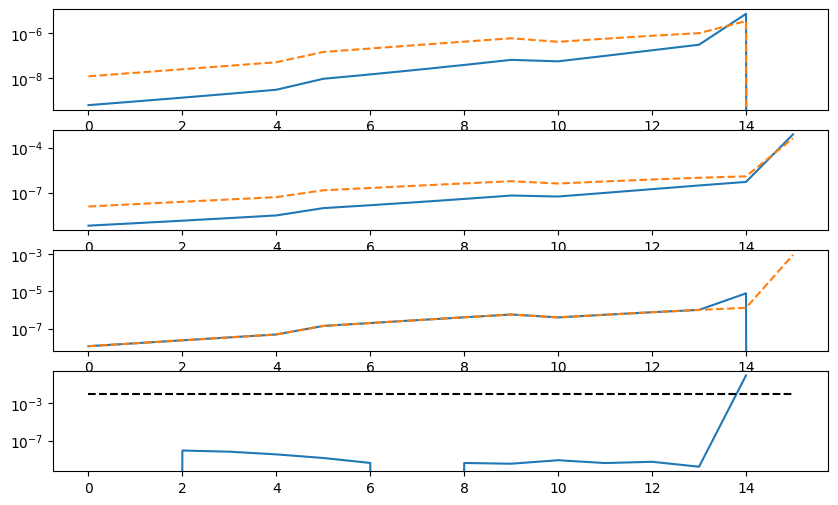

In [22]:
rho = torch.ones(16, dtype=torch.double)*40.
rho[5:10] = 20.
thick = torch.logspace(-1, 1.2, len(rho)-1, dtype=torch.double)
# thick = torch.ones_like(rho)[:-1]*10.

rte0 = rte_matrix(1./rho[:, None,None], thick[:,None,None], torch.tensor([1e3]), torch.tensor([1e-6])).squeeze().numpy()
#print(rte0.squeeze())

dm = (1./rho)*0.02
sgm_mat = (1./rho[:, None]) + torch.eye(len(rho))*dm

rte_perturb2 = drte_dsigma(1./rho[:, None,None], thick[:,None,None], torch.tensor([1e3]), torch.tensor([1e-6])).squeeze().numpy()


rte_perturb = rte_matrix(sgm_mat[:,:, None, None], thick[:,None, None,None], torch.tensor([1e3]), torch.tensor([1e-6])).squeeze().numpy()
rte_perturb = rte_perturb-rte0


# ends = slice(1, len(rho)-1)
ends = slice(None, None)

fig,axs = plt.subplots(4, 1, figsize=(10, 6))
axs[0].semilogy(np.abs(rte_perturb[ends].real))
axs[0].semilogy(np.abs(rte_perturb[ends].imag), '--')

axs[1].semilogy(np.abs(rte_perturb2[ends].real))
axs[1].semilogy(np.abs(rte_perturb2[ends].imag), '--')

axs[2].semilogy(np.abs(rte_perturb[ends]))
axs[2].semilogy(np.abs(rte_perturb2[ends]), '--')

axs[3].semilogy((np.abs(rte_perturb2[ends]-rte_perturb[ends])/np.abs(rte_perturb[ends])))
axs[3].semilogy(np.arange(len(rte_perturb)), np.ones(len(rte_perturb))*0.01, 'k--')

In [10]:
class ForwardMatrix(ForwardLaplace3):
    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.omega = -1j*s[None, None, :]
                
                if self.tmp_u0 is None: self.tmp_u0 = u0(self.omega, self.lmb)
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz) / self.tmp_u0 

                intg = rte_matrix(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                if self.waveform is not None:
                    intg /= -1j*self.omega
                return torch.squeeze(intg).real

            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res[None, ...] *= self.lmb**2 / c.fourpi
            return res.swapaxes(-2,-1)

        hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance, smp_per_decade=10)
        r,HR = hkl1.range(self.rmin, self.rmax)
        if self.geomz is None:
            self.geomz = self.source.geomz(self.receiver, r).to(torch.double)
            self.r=r
        else:
            assert torch.all(self.r==r)
        Ht = torch.einsum('...ik,...jk',  self.geomz, HR)

        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht, self.t2t).mT.squeeze()
        else:
            return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()  
        
    def jacobian(self):
        def wvlngth_integrand(wave_length):
            lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                omega = -1j*s[None, None, :]
                
                tmp_u0 = u0(omega, lmb)
                intg = drte_dsigma(self.sigma, self.thick, omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz) / tmp_u0 

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                if self.waveform is not None:
                    intg /= -1j*omega
                return torch.squeeze(intg).real

            res = invLaplace(s_integrand, device=self.device, n_coefficients=8)(self.t_eval)
            res[None, ...] *= lmb**2 / c.fourpi
            return res.swapaxes(-2,-1)

        hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=1e-6, smp_per_decade=10)
        r,HR = hkl1.range(self.rmin, self.rmax)
        if self.geomz is None:
            self.geomz = self.source.geomz(self.receiver, r).to(torch.double)
            self.r=r
        else:
            assert torch.all(self.r==r)
        Ht = torch.einsum('...ik,...jk',  self.geomz, HR)

        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht, self.t2t).mT.squeeze()
        else:
            return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()  

    def __call__(self, rho, thickness, jac=False):
        self.rho = ((rho+0j)[..., None, None])#.to(self.device)
        if rho.ndim > thickness.ndim:
            thickness = thickness[:, None, ...]
        self.thick = ((thickness+0j)[..., None, None])#.to(self.device)
        if jac:
            G = self.jacobian()
            return G*c.mu0 / rho[:, None]**2
        else:            
            return self.forward()*c.mu0

In [11]:
from anemone.experiment import Loop, Receiver, Waveform

t = torch.logspace(-5, -3, 40)
tx = Loop.square(40)
rx = Receiver()
waveform = Waveform.example()


In [12]:
fwr1 = ForwardMatrix(tx, rx, t, waveform)
G1 = fwr1(rho, thick, jac=True)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [13]:
fwr0 = ForwardLaplace3(tx, rx, t, waveform)
fwr1 = ForwardMatrix(tx, rx, t, waveform)

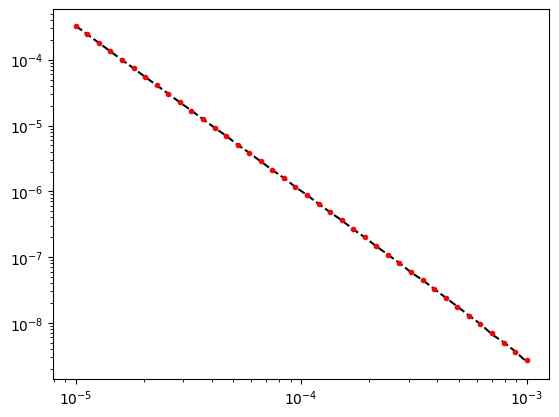

In [14]:
rho = torch.ones(16, dtype=torch.double)*40.
# rho[5:10] = 30.
thick = torch.logspace(-1, 1.2, len(rho)-1, dtype=torch.double)
dbdt0 = fwr0(rho, thick)
dbdt1 = fwr1(rho, thick)

plt.figure()
plt.loglog(fwr0.times, dbdt0, 'k--')
plt.loglog(fwr1.times, dbdt1, 'r.')

In [15]:
# %%timeit
# dbdt1 = fwr1(rho, thick)

In [16]:
# %%timeit
dm = rho*0.02
rho_mat = rho[:, None] + torch.eye(len(rho))*dm
#if 'dbdt_mat' not in locals():
dbdt_mat = fwr0(rho_mat, thick)
G0 = (dbdt_mat - dbdt0[None, :]) / dm[:, None]
# G0 = G0.numpy()

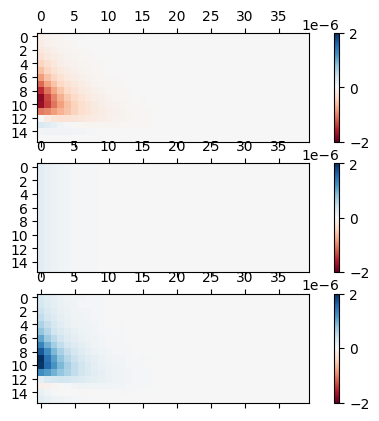

In [18]:
import matplotlib.pyplot as plt
import numpy as np
vlim = 2e-6#torch.abs(G0).max()

fig,axs = plt.subplots(3,1)
pcm = axs[0].matshow(G0, cmap='RdBu', vmin=-vlim, vmax=vlim)
plt.colorbar(pcm)

pcm = axs[1].matshow(G1, cmap='RdBu', vmin=-vlim, vmax=vlim)
plt.colorbar(pcm)

pcm = axs[2].matshow(G1-G0, cmap='RdBu', vmin=-vlim, vmax=vlim)
plt.colorbar(pcm)


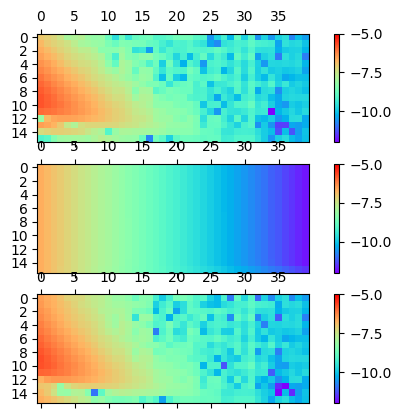

In [19]:
import matplotlib.pyplot as plt
import numpy as np

fig,axs = plt.subplots(3,1)
pcm = axs[0].matshow(torch.log10(torch.abs(G0)), cmap='rainbow', vmin=-12, vmax=-5)
plt.colorbar(pcm)

pcm = axs[1].matshow(torch.log10(torch.abs(G1)), cmap='rainbow', vmin=-12, vmax=-5)
plt.colorbar(pcm)

pcm = axs[2].matshow(torch.log10(torch.abs(G1-G0)), cmap='rainbow', vmin=-12, vmax=-5)
plt.colorbar(pcm)
